In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable
from pathlib import Path

In [3]:
ROOT = Path.cwd().parent
DATA = ROOT    / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [4]:
C15_ratio    = pd.read_excel(DATA / 'params-1.xlsx', sheet_name='C15_ratio', index_col=0)
C16_23_ratio = pd.read_excel(DATA / 'params-1.xlsx', sheet_name='C16_23_ratio', index_col=0)
C24_35_ratio = pd.read_excel(DATA / 'params-1.xlsx', sheet_name='C24_35_ratio', index_col=0)
C35_ratio    = pd.read_excel(DATA / 'params-1.xlsx', sheet_name='C35_ratio', index_col=0)

In [5]:
C35_ratio

,AFG,ALB,DZA,AGO,ARG,SUN,AUS,AUT,BHS,BHR,...,TUR,UGA,ARE,GBR,TZA,USA,URY,VEN,VNM,YEM
1931,10.0,10.0,10.0,10.0,10.0,5.0,10.0,15.0,10.0,10.0,...,1.0,10.0,10.0,24,10.0,10.0,10.0,10.0,10.0,10.0
1932,10.0,10.0,10.0,10.0,10.0,5.0,10.0,15.0,10.0,10.0,...,1.0,10.0,10.0,24,10.0,10.0,10.0,10.0,10.0,10.0
1933,10.0,10.0,10.0,10.0,10.0,5.0,10.0,15.0,10.0,10.0,...,1.0,10.0,10.0,24,10.0,10.0,10.0,10.0,10.0,10.0
1934,10.0,10.0,10.0,10.0,10.0,5.0,10.0,15.0,10.0,10.0,...,1.0,10.0,10.0,24,10.0,10.0,10.0,10.0,10.0,10.0
1935,10.0,10.0,10.0,10.0,10.0,5.0,10.0,15.0,10.0,10.0,...,1.0,10.0,10.0,24,10.0,10.0,10.0,10.0,10.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018,11.3,11.3,11.3,11.3,11.3,15.0,11.3,5.7,11.3,11.3,...,25.5,11.3,11.3,10,11.3,10.0,11.3,11.3,11.3,11.3
2019,10.0,10.0,10.0,10.0,10.0,15.0,10.0,6.3,10.0,10.0,...,25.0,10.0,10.0,10,10.0,10.0,10.0,10.0,10.0,10.0
2020,10.0,10.0,10.0,10.0,10.0,15.0,10.0,6.3,10.0,10.0,...,25.0,10.0,10.0,10,10.0,10.0,10.0,10.0,10.0,10.0
2021,10.0,10.0,10.0,10.0,10.0,15.0,10.0,6.3,10.0,10.0,...,25.0,10.0,10.0,10,10.0,10.0,10.0,10.0,10.0,10.0


In [5]:
world_map = gpd.read_file(DATA / 'simplified-world-map/world-map.shp')
world_map = world_map.drop([31])
China_province_map = gpd.read_file(DATA / 'China-map/省.shp')
hk_row = China_province_map[China_province_map['省'] == '香港特别行政区'].copy()
mo_row = China_province_map[China_province_map['省'] == '澳门特别行政区'].copy()
hk_row = hk_row.assign(GID_0="HKG", COUNTRY="Hong Kong")[["GID_0", "COUNTRY", "geometry"]]
mo_row = mo_row.assign(GID_0="MAC", COUNTRY="Macau")[["GID_0", "COUNTRY", "geometry"]]
world_map = pd.concat([world_map, hk_row, mo_row], ignore_index=True)
world_map_eck4 = world_map.to_crs('ESRI:54012')
production_142 = pd.read_csv(DATA / 'production-142.csv', index_col=0)
economies_142 = production_142.columns.tolist()
mapping = pd.read_excel(DATA / 'contents.xlsx', sheet_name='merged_countries')  # parent, child, child_name
child_to_parent = dict(zip(mapping["child"], mapping["parent"]))

In [6]:
# Cell 1: pick year and assemble the four class series
YEAR = 2022
classes = {
    'C15':    C15_ratio.loc[YEAR],
    'C16–23': C16_23_ratio.loc[YEAR],
    'C24–35': C24_35_ratio.loc[YEAR],
    'C35+':   C35_ratio.loc[YEAR],
}

In [7]:
# Cell 2: remap child GID_0 to parent so values join correctly
wm = world_map_eck4.copy()
wm['GID_parent'] = wm['GID_0'].map(child_to_parent).fillna(wm['GID_0'])

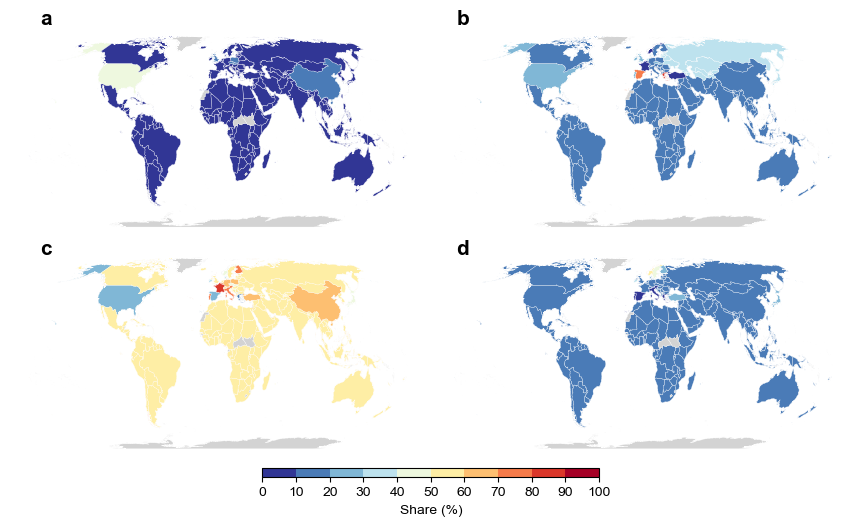

In [ ]:
# Cell 3: 2×2 panel map with shared discrete colorbar (10 bins, 0–100)
bounds = np.arange(0, 101, 10)          # 0,10,...,100
cmap   = plt.get_cmap('RdYlBu_r', 10)
norm   = BoundaryNorm(bounds, ncolors=10)

fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.0), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial'

for i, (ax, (name, values)) in enumerate(zip(axes.flat, classes.items())):
    g = wm.assign(value=wm['GID_parent'].map(values))
    g.plot(
        column='value', ax=ax, cmap=cmap, norm=norm,
        missing_kwds={'color': 'lightgrey', 'edgecolor': 'white', 'linewidth': 0.2},
        edgecolor='white', linewidth=0.2,
    )

    ax.set_axis_off()
    # ax.set_ylim(-7.2e6, 8.6e6)

# single shared colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal',
                    shrink=0.4, aspect=40, pad=0.02, ticks=bounds)
cbar.set_label('Share (%)')

fig.text(0.04, 0.99, 'a', fontdict={'size':15, 'weight': 'semibold'})
fig.text(0.53, 0.99, 'b', fontdict={'size':15, 'weight': 'semibold'})
fig.text(0.04, 0.53, 'c', fontdict={'size':15, 'weight': 'semibold'})
fig.text(0.53, 0.53, 'd', fontdict={'size':15, 'weight': 'semibold'})

fig.savefig(FIGURES / f'Supplementary-Figure-2.jpg', dpi=600, bbox_inches='tight')
plt.show()